&nbsp;
# <div align=center><font color=green> <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> : Classification & Regression</font></div>
# <div align=center> Part I </div>
## <div align=center>Zhongjian Jiang & Ziping Zhao</div>

**<div align=center> School of Information Science and Technology </div>**
**<div align=center>ShanghaiTech University, Shanghai, China</div>**

**<div align=center><font size="7">CS182: Introduction to Machine Learning<font/></div>**
    
**<div align=center><font size="7">http://cs182.sist.shanghaitech.edu.cn<font/></div>**

### <div align=center><font color=green> Sec. 1.1 1.3 1.5 1.6 1.7 1.8 1.9 1.17 2.6 of  <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> </font></div>

# <div align=Left>Learning Objectives</div>
<br />


- Be able to utilize `scikit-learn` for machine learning tasks.
<br />

- Introduction to regression & implementing regression models in `scikit-learn`.
<br />


- Introduction to classification & implementing classification models in `scikit-learn`.

Naive Bayes methods are a set of supervised learning algorithms based on applying Bayes’ theorem with the “naive” assumption of conditional independence between every pair of features given the value of the class variable. Bayes’ theorem states the following relationship, given class variable $y$ and dependent feature vector $x_1$ through $x_n$, :$P(y \mid x_1, \dots, x_n) = \frac{P(y) P(x_1, \dots, x_n \mid y)} {P(x_1, \dots, x_n)}$

Using the naive conditional independence assumption that $P(x_i | y, x_1, \dots, x_{i-1}, x_{i+1}, \dots, x_n) = P(x_i | y),$
for all $i$, this relationship is simplified to
$P(y \mid x_1, \dots, x_n) = \frac{P(y) \prod_{i=1}^{n} P(x_i \mid y)} {P(x_1, \dots, x_n)}$

Since $P(x_1, \dots, x_n)$ is constant given the input, we can use the following classification rule:

$$ \begin{align}\begin{aligned}P(y \mid x_1, \dots, x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)\\\Downarrow\\\hat{y} = \arg\max_y P(y) \prod_{i=1}^{n} P(x_i \mid y),\end{aligned}\end{align} $$
and we can use Maximum A Posteriori (MAP) estimation to estimate $P(y)$ and $P(x_i \mid y)$; the former is then the relative frequency of class $y$ in the training set.

The different naive Bayes classifiers differ mainly by the assumptions they make regarding the distribution of $P(x_i \mid y)$.

- Naive Bayes:
    + Gaussian Naive Bayes
    + <font color=blue>**GaussianNB** <font color=white> implements the Gaussian Naive Bayes algorithm for classification. The likelihood of the features is assumed to be Gaussian:

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma^2_y}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma^2_y}\right)$$
The parameters $\sigma_y$ and $\mu_y$ are estimated using maximum likelihood.

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
gnb = GaussianNB()
y_pred = gnb.fit(X_train, y_train).predict(X_test)
print("Number of mislabeled points out of a total %d points : %d"
      % (X_test.shape[0], (y_test != y_pred).sum()))

Number of mislabeled points out of a total 75 points : 4


In [2]:
?GaussianNB

- Naive Bayes:
    + Multinomial Naive Bayes
    + <font color=blue>**MultinomialNB** <font color=white> implements the naive Bayes algorithm for multinomially distributed data, and is one of the two classic naive Bayes variants used in text classification (where the data are typically represented as word vector counts, although tf-idf vectors are also known to work well in practice). The distribution is parametrized by vectors $\theta_y = (\theta_{y1},\ldots,\theta_{yn})$ for each class $y$, where $n$ is the number of features (in text classification, the size of the vocabulary) and $\theta_{yi}$ is the probability $P(x_i \mid y)$ of feature $i$ appearing in a sample belonging to class $y$.

The parameters $\theta_y$ is estimated by a smoothed version of maximum likelihood, i.e. relative frequency counting:

$$\hat{\theta}_{yi} = \frac{ N_{yi} + \alpha}{N_y + \alpha n}$$
where $N_{yi} = \sum_{x \in T} x_i$ is the number of times feature $i$ appears in a sample of class $y$ in the training set $T$, and $N_{y} = \sum_{i=1}^{n} N_{yi}$ is the total count of all features for class $y$.

The smoothing priors $\alpha \ge 0$ accounts for features not present in the learning samples and prevents zero probabilities in further computations. Setting $\alpha = 1$ is called Laplace smoothing, while $\alpha < 1$ is called Lidstone smoothing.

In [100]:
from sklearn.naive_bayes import MultinomialNB
?MultinomialNB

- Naive Bayes:
    + Complement Naive Bayes
    + <font color=blue>**ComplementNB** <font color=white> implements the complement naive Bayes (CNB) algorithm. CNB is an adaptation of the standard multinomial naive Bayes (MNB) algorithm that is particularly suited for imbalanced data sets. Specifically, CNB uses statistics from the complement of each class to compute the model’s weights. The inventors of CNB show empirically that the parameter estimates for CNB are more stable than those for MNB. Further, CNB regularly outperforms MNB (often by a considerable margin) on text classification tasks.

In [101]:
from sklearn.naive_bayes import ComplementNB
?ComplementNB

- Naive Bayes:
    + Bernoulli Naive Bayes
    + <font color=blue>**BernoulliNB** <font color=white> implements the naive Bayes training and classification algorithms for data that is distributed according to multivariate Bernoulli distributions; i.e., there may be multiple features but each one is assumed to be a binary-valued (Bernoulli, boolean) variable. Therefore, this class requires samples to be represented as binary-valued feature vectors; if handed any other kind of data, a BernoulliNB instance may binarize its input (depending on the binarize parameter).

The decision rule for Bernoulli naive Bayes is based on

$$P(x_i \mid y) = P(x_i = 1 \mid y) x_i + (1 - P(x_i = 1 \mid y)) (1 - x_i)$$
which differs from multinomial NB’s rule in that it explicitly penalizes the non-occurrence of a feature $i$ that is an indicator for class $y$, where the multinomial variant would simply ignore a non-occurring feature.

In the case of text classification, word occurrence vectors (rather than word count vectors) may be used to train and use this classifier. BernoulliNB might perform better on some datasets, especially those with shorter documents. It is advisable to evaluate both models, if time permits.

In [102]:
from sklearn.naive_bayes import BernoulliNB
?BernoulliNB

- Naive Bayes:
    + Categorical Naive Bayes
    + <font color=blue>**CategoricalNB** <font color=white> implements the categorical naive Bayes algorithm for categorically distributed data. It assumes that each feature, which is described by the index $i$, has its own categorical distribution.

For each feature $i$ in the training set $X$, CategoricalNB estimates a categorical distribution for each feature i of X conditioned on the class y. The index set of the samples is defined as $J = \{ 1, \dots, m \}$, with $m$ as the number of samples.

In [32]:
from sklearn.naive_bayes import CategoricalNB
?CategoricalNB

- Naive Bayes:
    + Out-of-core naive Bayes model fitting
    
    Naive Bayes models can be used to tackle large scale classification problems for which the full training set might not fit in memory. To handle this case, MultinomialNB, BernoulliNB, and GaussianNB expose a partial_fit method that can be used incrementally as done with other classifiers as demonstrated in Out-of-core classification of text documents. All naive Bayes classifiers support sample weighting.

    Contrary to the fit method, the first call to partial_fit needs to be passed the list of all the expected class labels.

    For an overview of available strategies in scikit-learn, see also the out-of-core learning documentation.

- Parametric Classfication:
    + LinearDiscriminantAnalysis
    + QuadraticDiscriminantAnalysis

Linear Discriminant Analysis (LinearDiscriminantAnalysis) and Quadratic Discriminant Analysis (QuadraticDiscriminantAnalysis) are two classic classifiers, with, as their names suggest, a linear and a quadratic decision surface, respectively.

These classifiers are attractive because they have closed-form solutions that can be easily computed, are inherently multiclass, have proven to work well in practice, and have no hyperparameters to tune.

LinearDiscriminantAnalysis can be used to perform supervised dimensionality reduction, by projecting the input data to a linear subspace consisting of the directions which maximize the separation between classes (in a precise sense discussed in the mathematics section below). The dimension of the output is necessarily less than the number of classes, so this is in general a rather strong dimensionality reduction, and only makes sense in a multiclass setting.

This is implemented in the transform method. The desired dimensionality can be set using the n_components parameter. This parameter has no influence on the fit and predict methods.

In [103]:
?LinearDiscriminantAnalysis

QDA can be derived from simple probabilistic models which model the class conditional distribution of the data $P(X|y=k)$ for each class $k$. Predictions can then be obtained by using Bayes’ rule, for each training sample $x \in \mathcal{R}^d$:

$$P(y=k | x) = \frac{P(x | y=k) P(y=k)}{P(x)} = \frac{P(x | y=k) P(y = k)}{ \sum_{l} P(x | y=l) \cdot P(y=l)}$$
and we select the class $k$ which maximizes this posterior probability.

More specifically, for linear and quadratic discriminant analysis, $P(x|y)$ is modeled as a multivariate Gaussian distribution with density:

$$P(x | y=k) = \frac{1}{(2\pi)^{d/2} |\Sigma_k|^{1/2}}\exp\left(-\frac{1}{2} (x-\mu_k)^t \Sigma_k^{-1} (x-\mu_k)\right)$$
where $d$ is the number of features.

According to the model above, the log of the posterior is:

$$\begin{split}\log P(y=k | x) &= \log P(x | y=k) + \log P(y = k) + Cst \\ &= -\frac{1}{2} \log |\Sigma_k| -\frac{1}{2} (x-\mu_k)^t \Sigma_k^{-1} (x-\mu_k) + \log P(y = k) + Cst,\end{split}$$
where the constant term $Cst$ corresponds to the denominator $P(x)$, in addition to other constant terms from the Gaussian. The predicted class is the one that maximises this log-posterior.

In [104]:
?QuadraticDiscriminantAnalysis

In [3]:
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

plt.rcParams['font.sans-serif'] = ['KaiTi']  
plt.rcParams["axes.unicode_minus"] = False  


iris = datasets.load_iris()
X = iris.data  
y = iris.target
target_names = iris.target_names 


pca = PCA(n_components=2)  
X_r_pca = pca.fit_transform(X) 


lda = LinearDiscriminantAnalysis(n_components=2)  
X_r_lda = lda.fit_transform(X, y)  


In [4]:
# QDA
qda = QuadraticDiscriminantAnalysis()  
qda.fit(X, y) 
y_pred = qda.predict(X)  

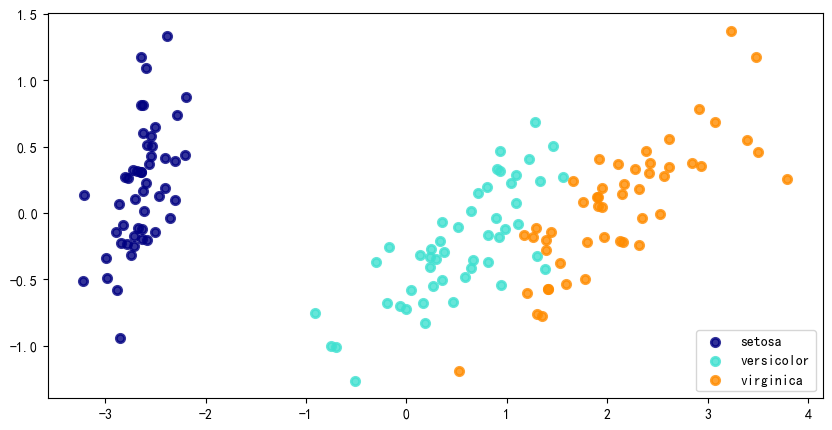

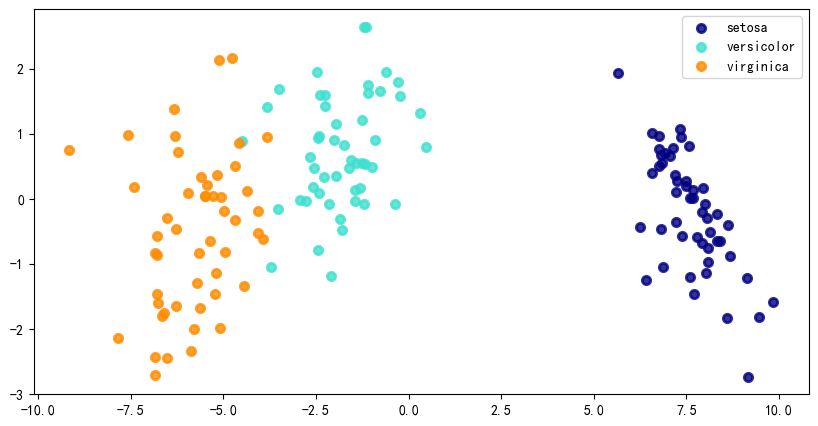

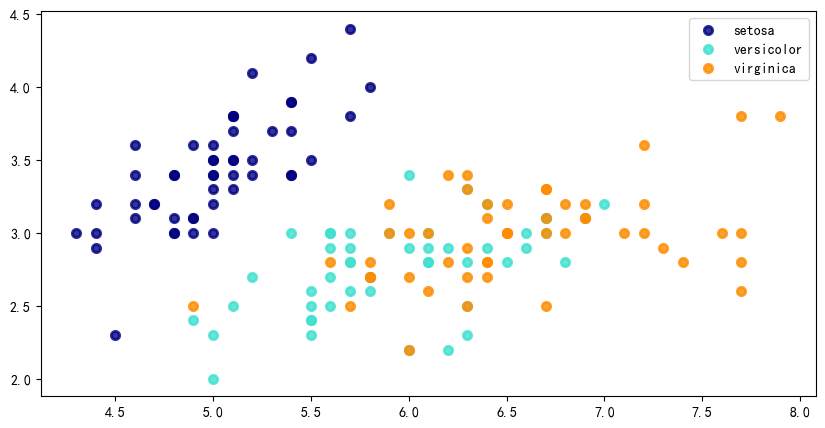

In [5]:
plt.figure(figsize=(10, 5))
colors = ['navy', 'turquoise', 'darkorange']
lw = 2

for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(X_r_pca[y == i, 0], X_r_pca[y == i, 1], color=color, alpha=0.8, lw=lw, label=target_name)
plt.legend(loc='best', shadow=False, scatterpoints=1)



plt.figure(figsize=(10, 5))
for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(X_r_lda[y == i, 0], X_r_lda[y == i, 1], color=color, alpha=0.8, lw=lw, label=target_name)
plt.legend(loc='best', shadow=False, scatterpoints=1)


plt.figure(figsize=(10, 5))
for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(X[y_pred == i, 0], X[y_pred == i, 1], color=color, alpha=0.8, lw=lw, label=target_name)
plt.legend(loc='best', shadow=False, scatterpoints=1)


plt.show()


## <div align=Left>Linear Models</div>

<br />


- Ordinary Least Squares:
    + $y(w, x) = w_0 + w_1 x_1 + ... + w_p x_p$
    + $\min_{w}|| X w - y||_2^2$
    
    
    ```python
        from sklearn import linear_model
        reg = linear_model.LinearRegression(fit_intercept=True)
        # x:[[0, 0], [1, 1], [2, 2]], y:[0, 1, 2]
        reg.fit([[0, 0], [1, 1], [2, 2]], [0, 1, 2])
    ```
    

In [6]:
from sklearn import linear_model
reg = linear_model.LinearRegression(fit_intercept=True) 
reg.fit([[0, 0], [1, 1], [2, 2]], [0, 1, 2])
print(reg.coef_)
print(reg.intercept_)

[0.5 0.5]
1.1102230246251565e-16


In [105]:
?linear_model.LinearRegression

In [7]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error

# Load the diabetes dataset
diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True)

# Use only one feature
diabetes_X = diabetes_X[:, np.newaxis, 2]

# Split the data into training/testing sets
diabetes_X_train = diabetes_X[:-20]
diabetes_X_test = diabetes_X[-20:]

# Split the targets into training/testing sets
diabetes_y_train = diabetes_y[:-20]
diabetes_y_test = diabetes_y[-20:]

Coefficients: 
 [938.23786125]
Mean squared error: 2548.07


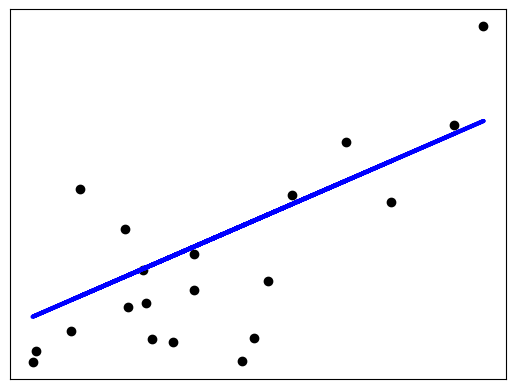

(([], []), ([], []), None)

In [8]:
# Create linear regression object
regr = linear_model.LinearRegression()
# Train the model using the training sets
regr.fit(diabetes_X_train, diabetes_y_train)
# Make predictions using the testing set
diabetes_y_pred = regr.predict(diabetes_X_test)
# The coefficients
print("Coefficients: \n", regr.coef_)
# The mean squared error
print("Mean squared error: %.2f" % mean_squared_error(diabetes_y_test, diabetes_y_pred))
# Plot outputs
plt.scatter(diabetes_X_test, diabetes_y_test, color="black")
plt.plot(diabetes_X_test, diabetes_y_pred, color="blue", linewidth=3)
plt.xticks(()),plt.yticks(()),plt.show()

- Polynomial Regression:

In [9]:
# Generate datasets
import numpy as np
import matplotlib.pyplot as plt

x = np.random.uniform(-3, 3, size=100)
X = x.reshape(-1, 1)
y = 0.5 * x**2 + x + np.random.normal(0, 1, 100)

In [10]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
poly.fit(X)
X2 = poly.transform(X)

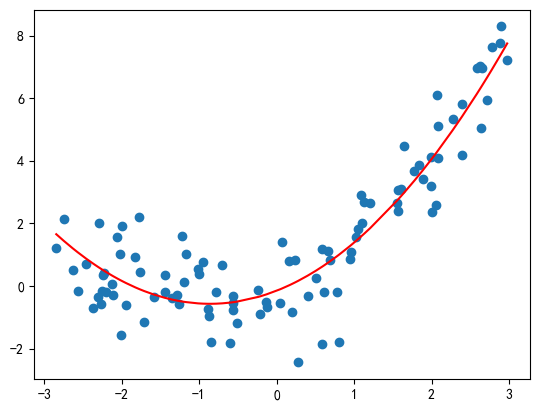

In [11]:
from sklearn.linear_model import LinearRegression

lin_reg2 = LinearRegression()
lin_reg2.fit(X2, y)
y_predict2 = lin_reg2.predict(X2)
plt.scatter(x, y)
plt.plot(np.sort(x), y_predict2[np.argsort(x)], color='r')
plt.show()

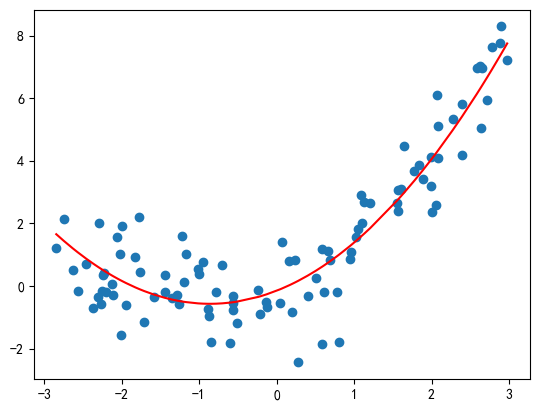

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt


poly_reg = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("std_scaler", StandardScaler()),
    ("lin_reg", LinearRegression())
])

poly_reg.fit(X, y)
y_predict = poly_reg.predict(X)
plt.scatter(x, y)
plt.plot(np.sort(x), y_predict[np.argsort(x)], color='r')
plt.show()

- Logit Regression:
    
    
    
    ```python
        import sklearn
 
        sklearn.linear_model.LogisticRegression(penalty='l2', 
          dual=False, tol=0.0001, C=1.0, fit_intercept=True, 
          intercept_scaling=1, class_weight=None, 
          random_state=None, solver='liblinear', max_iter=100, 
          multi_class='ovr', verbose=0, warm_start=False, n_jobs=1)
    ```
    

In [13]:
import sklearn
 
sklearn.linear_model.LogisticRegression(penalty='l2', 
          dual=False, tol=0.0001, C=1.0, fit_intercept=True, 
          intercept_scaling=1, class_weight=None, 
          random_state=None, solver='liblinear', max_iter=100, 
          multi_class='ovr', verbose=0, warm_start=False, n_jobs=1)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,100
,multi_class,'ovr'


In [50]:
?sklearn.linear_model.LogisticRegression

In [14]:
import numpy as np
from sklearn import linear_model, datasets
from sklearn.model_selection import train_test_split


 
iris = datasets.load_iris()
x_data = iris.data
y_label = [1 if i>=1 else 0 for i in iris.target]
print("x_data: \n", x_data[:10])
print("\n")
print("label_data: \n",y_label[:10])


 
X_train, X_test, Y_train, Y_test = train_test_split(x_data, y_label, test_size=0.3, random_state=0)

x_data: 
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]]


label_data: 
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [16]:

 
log_reg = linear_model.LogisticRegression()
log_reg.fit(X_train, Y_train)


 
test_data_proba = log_reg.predict_proba(X_test)
accuracy = log_reg.score(X_test, Y_test)
 
print("test data proba value: \n", test_data_proba[:10])
print("\n"*2)
print("test data true value: \n", Y_test[:10])
print("\n"*2)
print("test data accuracy is :", accuracy)

test data proba value: 
 [[8.61793211e-04 9.99138207e-01]
 [1.86522383e-02 9.81347762e-01]
 [9.84085117e-01 1.59148834e-02]
 [6.37833437e-05 9.99936217e-01]
 [9.70821822e-01 2.91781785e-02]
 [1.34623279e-04 9.99865377e-01]
 [9.80582917e-01 1.94170833e-02]
 [3.95318245e-03 9.96046818e-01]
 [2.65559776e-03 9.97344402e-01]
 [2.15688756e-02 9.78431124e-01]]



test data true value: 
 [1, 1, 0, 1, 0, 1, 0, 1, 1, 1]



test data accuracy is : 1.0


- Ridge Regression:
    + $\min_{w}|| X w - y||_2^2 + \alpha || w ||_2^2$
    
    
    ```python
        from sklearn import linear_model
        reg = linear_model.Ridge(alpha=.5)
        reg.fit([[0, 0], [0, 0], [1, 1]], [0, .1, 1])
    ```
    

In [53]:
from sklearn import linear_model
reg = linear_model.Ridge(alpha=.5)
reg.fit([[0, 0], [0, 0], [1, 1]], [0, .1, 1])
print(reg.coef_)
print(reg.intercept_)

[0.34545455 0.34545455]
0.13636363636363638


In [106]:
?linear_model.Ridge

https://stats.stackexchange.com/questions/151304/why-is-ridge-regression-called-ridge-why-is-it-needed-and-what-happens-when

- LASSO:
    + $\min_{w} \frac{1}{2 n_{samples}}|| X w - y||_2^2+ \alpha || w ||_1$
    
    
    ```python
        from sklearn import linear_model
        reg = linear_model.Lasso(alpha=0.1)
        reg.fit([[0, 0], [1, 1]], [0, 1])
        reg.predict([[1, 1]])
    ```
    

In [55]:
from sklearn import linear_model
reg = linear_model.Lasso(alpha=0.1)
reg.fit([[0, 0], [1, 1]], [0, 1])
reg.predict([[1, 1]])
print(reg.coef_)
print(reg.intercept_)

[0.6 0. ]
0.2


In [56]:
?linear_model.Lasso

- Elastic-Net:
    + $\min_{w} \frac{1}{2 n_{samples}}|| X w - y||_2^2+ \alpha \rho || w ||_1 + \frac{\alpha (1-\rho)}{2} || w ||_2^2$
    
    
    ```python
        from sklearn import linear_model
        reg = linear_model.ElasticNet(alpha=0.1)
        reg.fit([[0, 0], [1, 1]], [0, 1])
        reg.predict([[1, 1]])
    ```
    

In [57]:
?linear_model.ElasticNet

## <div align=Left>Stochastic Gradient Descent</div>

<br />


- Stochastic Gradient Descent:
    
    
    ```python
        from sklearn.linear_model import SGDClassifier
        X = [[0., 0.], [1., 1.]]
        y = [0, 1]
        clf = SGDClassifier(loss="hinge", penalty="l2", max_iter=5)
        clf.fit(X, y)
    ```

- Stochastic Gradient Descent:
    
    
    ```python
        from sklearn.linear_model import SGDClassifier
        X = [[0., 0.], [1., 1.]]
        y = [0, 1]
        clf = SGDClassifier(loss="hinge", penalty="l2", max_iter=5)
        clf.fit(X, y)
    ```

In [17]:
from sklearn.linear_model import SGDClassifier
X = [[0., 0.], [1., 1.]]
y = [0, 1]
clf = SGDClassifier(loss="hinge", penalty="l2", max_iter=5)
clf.fit(X, y)

D:\programs\anaconda3\envs\cs182\lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,5
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


$$HingeLoss = \frac{1}{N}\sum_{i=1}^{N} \max(0, 1-y_i \cdot \hat{y}_i)      $$

In [60]:
?linear_model.SGDClassifier

In [18]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_blobs
from sklearn.linear_model import SGDClassifier

# we create 50 separable points
X, Y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)

# fit the model
clf = SGDClassifier(loss="hinge", alpha=0.01, max_iter=200) # hinge

clf.fit(X, Y)

,loss,'hinge'
,penalty,'l2'
,alpha,0.01
,l1_ratio,0.15
,fit_intercept,True
,max_iter,200
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [96]:
?sklearn.metrics.hinge_loss

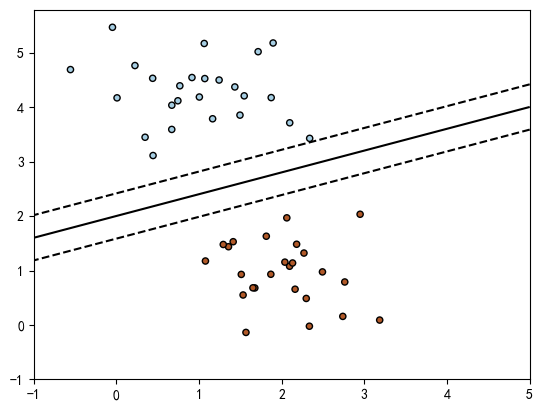

In [62]:
# plot the line, the points, and the nearest vectors to the plane
xx = np.linspace(-1, 5, 10)
yy = np.linspace(-1, 5, 10)

X1, X2 = np.meshgrid(xx, yy)
Z = np.empty(X1.shape)
for (i, j), val in np.ndenumerate(X1):
    x1 = val
    x2 = X2[i, j]
    p = clf.decision_function([[x1, x2]])
    Z[i, j] = p[0]
levels = [-1.0, 0.0, 1.0]
linestyles = ["dashed", "solid", "dashed"]
colors = "k"
plt.contour(X1, X2, Z, levels, colors=colors, linestyles=linestyles)
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Paired, edgecolor="black", s=20)

plt.axis("tight")
plt.show()

In [19]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import SGDClassifier

# import some data to play with
iris = datasets.load_iris()

# we only take the first two features. We could
# avoid this ugly slicing by using a two-dim dataset
X = iris.data[:, :2]
y = iris.target
colors = "bry"

# shuffle
idx = np.arange(X.shape[0])
np.random.seed(13)
np.random.shuffle(idx)
X = X[idx]
y = y[idx]

# standardize
mean = X.mean(axis=0)
std = X.std(axis=0)
X = (X - mean) / std

clf = SGDClassifier(alpha=0.001, max_iter=100).fit(X, y)

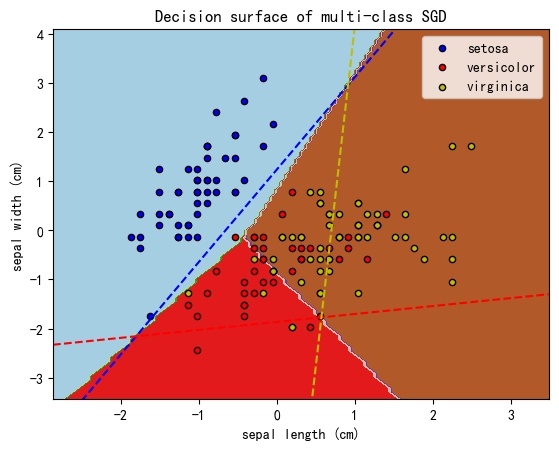

In [22]:
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    cmap=plt.cm.Paired,
    ax=ax,
    response_method="predict",
    xlabel=iris.feature_names[0],
    ylabel=iris.feature_names[1],
)
plt.axis("tight")

# Plot also the training points
for i, color in zip(clf.classes_, colors):
    idx = np.where(y == i)
    plt.scatter(
        X[idx, 0],
        X[idx, 1],
        c=color,
        label=iris.target_names[i],
        edgecolor="black",
        s=20,
    )
plt.title("Decision surface of multi-class SGD")
plt.axis("tight")

# Plot the three one-against-all classifiers
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()
coef = clf.coef_
intercept = clf.intercept_


def plot_hyperplane(c, color):
    def line(x0):
        return (-(x0 * coef[c, 0]) - intercept[c]) / coef[c, 1]

    plt.plot([xmin, xmax], [line(xmin), line(xmax)], ls="--", color=color)


for i, color in zip(clf.classes_, colors):
    plot_hyperplane(i, color)
plt.legend()
plt.show()

In [23]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn import linear_model

# we create 20 points
np.random.seed(0)
X = np.r_[np.random.randn(10, 2) + [1, 1], np.random.randn(10, 2)]
y = [1] * 10 + [-1] * 10
sample_weight = 100 * np.abs(np.random.randn(20))
# and assign a bigger weight to the last 10 samples
sample_weight[:10] *= 10



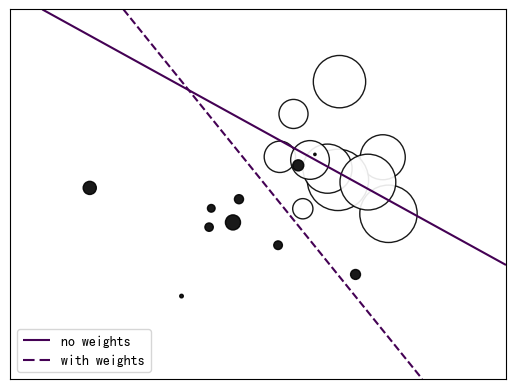

In [24]:
# plot the weighted data points
xx, yy = np.meshgrid(np.linspace(-4, 5, 500), np.linspace(-4, 5, 500))
fig, ax = plt.subplots()
ax.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    s=sample_weight,
    alpha=0.9,
    cmap=plt.cm.bone,
    edgecolor="black",
)

# fit the unweighted model
clf = linear_model.SGDClassifier(alpha=0.01, max_iter=100)
clf.fit(X, y)
Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
no_weights = ax.contour(xx, yy, Z, levels=[0], linestyles=["solid"])

# fit the weighted model
clf = linear_model.SGDClassifier(alpha=0.01, max_iter=100)
clf.fit(X, y, sample_weight=sample_weight)
Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
samples_weights = ax.contour(xx, yy, Z, levels=[0], linestyles=["dashed"])
no_weights_handles, _ = no_weights.legend_elements()
weights_handles, _ = samples_weights.legend_elements()
ax.legend(
    [no_weights_handles[0], weights_handles[0]],
    ["no weights", "with weights"],
    loc="lower left",
)

ax.set(xticks=(), yticks=())
plt.show()

- Stochastic Gradient Descent:
    
    
    ```python
        from sklearn.linear_model import SGDRegressor
        X = [[0., 0.], [1., 1.]]
        y = [0, 1]
        clf = SGDRegressor(loss="squared_loss")
        clf.fit(X, y)
    ```

In [67]:
?linear_model.SGDRegressor

## <div align=Left>Covariance Estimation</div>

<br />

Many statistical problems require the estimation of a population’s covariance matrix, which can be seen as an estimation of data set scatter plot shape. Most of the time, such an estimation has to be done on a sample whose properties (size, structure, homogeneity) have a large influence on the estimation’s quality. The sklearn.covariance package provides tools for accurately estimating a population’s covariance matrix under various settings.

We assume that the observations are independent and identically distributed (i.i.d.).

$$ S = \frac{1}{n - 1}\sum_{i=1}^n x x^\top $$

The covariance matrix of a data set is known to be well approximated by the classical maximum likelihood estimator (or “empirical covariance”), provided the number of observations is large enough compared to the number of features (the variables describing the observations). More precisely, the Maximum Likelihood Estimator of a sample is an asymptotically unbiased estimator of the corresponding population’s covariance matrix.

The empirical covariance matrix of a sample can be computed using the empirical_covariance function of the package, or by fitting an EmpiricalCovariance object to the data sample with the EmpiricalCovariance.fit method. Be careful that results depend on whether the data are centered, so one may want to use the assume_centered parameter accurately. More precisely, if assume_centered=False, then the test set is supposed to have the same mean vector as the training set. If not, both should be centered by the user, and assume_centered=True should be used.

In [91]:
?sklearn.covariance.empirical_covariance

- Sparse inverse covariance:
    
    
<p>The mathematical formulation is the following:</p>
<div class="math notranslate nohighlight">
\[\hat{K} = \mathrm{argmin}_K \big(
            \mathrm{tr} S K - \mathrm{log} \mathrm{det} K
            + \alpha \|K\|_1
            \big)\]</div>
<p>Where <span class="math notranslate nohighlight">\(K\)</span> is the precision matrix to be estimated, and <span class="math notranslate nohighlight">\(S\)</span> is the
sample covariance matrix. <span class="math notranslate nohighlight">\(\|K\|_1\)</span> is the sum of the absolute values of
off-diagonal coefficients of <span class="math notranslate nohighlight">\(K\)</span>. The algorithm employed to solve this
problem is the GLasso algorithm, from the Friedman 2008 Biostatistics
paper. It is the same algorithm as in the R <code class="docutils literal notranslate"><span class="pre">glasso</span></code> package.</p>

- Bayesian Regression:
    + Bayesian Ridge Regression
    + $p(w \mid \lambda)=\mathcal{N}(w \mid 0, \lambda^{-1} \mathbf{I})$
    
    
    ```python
        from sklearn import linear_model
        X = [[0., 0.], [1., 1.], [2., 2.], [3., 3.]]
        Y = [0., 1., 2., 3.]
        reg = linear_model.BayesianRidge()
        reg.fit(X, Y)
    ```
    

In [33]:
from sklearn import linear_model
X = [[0., 0.], [1., 1.], [2., 2.], [3., 3.]]
Y = [0., 1., 2., 3.]
reg = linear_model.BayesianRidge()
reg.fit(X, Y)
print(reg.coef_)
print(reg.intercept_)

[0.49999993 0.49999993]
1.9999946720972162e-07


In [88]:
?linear_model.BayesianRidge

In [46]:
from sklearn.neural_network import MLPRegressor,MLPClassifier

In [107]:
?MLPRegressor

In [48]:
?MLPClassifier